# Distributions, Transformations, and Outliers

**INFSCI/PS 0702 · Companion notebook to Lecture 10 (Weights, Raises, Outliers and GOATs)**

## Part 1: Introduction
In this notebook you will learn, step by step, how to:

1. Run Python code in a Jupyter notebook (no experience needed!)
2. Generate random numbers and **simulate** data from different distributions
3. Recognize common distributions: **uniform, normal, lognormal, exponential, Pareto, binomial, and Poisson**
4. Read **histograms** and **CDFs** (cumulative distribution functions)
5. Use simulation to see **why** some things are normal and others are lognormal (body weight, raises, running speed, GOATs)
6. Apply a **log transformation** and know when it helps
7. **Scale** and **normalize** data (min-max, z-score, robust scaling)
8. **Identify outliers** with three different rules, and decide what to do with them



In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats



## Part 2: Random Numbers and Your First Distribution

A **distribution** describes how often different values occur. To *simulate* a distribution, we ask the computer for many random numbers that follow a particular pattern.

### 2.1 Drawing random numbers

Our random number generator `rng` has a method for each distribution. Let's draw 10 numbers from a **normal** distribution with a mean of 170 and a standard deviation of 10, a rough model of adult heights in centimeters.

**Note:** 
* A random seed is the starting point for a computer’s random number generator.
* Computers can’t produce truly random numbers on their own.
* Instead, they use a formula that generates a long sequence of numbers that look random.
* The seed decides where in that sequence the generator starts.
* Use the same seed and you get exactly the same “random” numbers every time; use a different seed (or none) and you get different ones.

In [49]:
rng = np.random.default_rng(42)
heights = rng.normal(loc=170, scale=10, size=10)   # loc = mean, scale = standard deviation
print(heights.round(1))

[173.  159.6 177.5 179.4 150.5 157.  171.3 166.8 169.8 161.5]


### 2.2 Seeing the shape with a histogram

Ten numbers aren't enough to see a pattern. Let's draw **10,000** and make a **histogram**: a bar chart where each bar counts how many values fall in a range (a "bin").

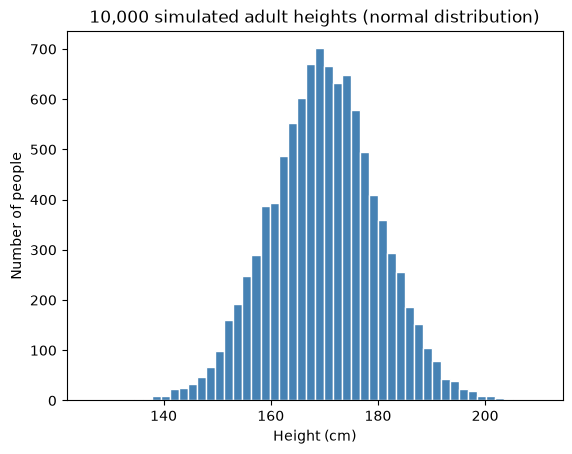

In [50]:
heights = rng.normal(loc=170, scale=10, size=10000)

plt.hist(heights, bins=50, color="steelblue", edgecolor="white")
plt.xlabel("Height (cm)")
plt.ylabel("Number of people")
plt.title("10,000 simulated adult heights (normal distribution)")
plt.show()

That's the famous **bell curve**. Key features of the normal distribution:

- It is **symmetric**: the left and right sides are mirror images.
- The **mean** and **median** are (almost) the same, right in the middle.
- About **68%** of values are within 1 standard deviation of the mean, **95%** within 2, and **99.7%** within 3. This is the "68-95-99.7 rule."

Let's check the 68-95-99.7 rule with our simulated data.

In [51]:
mean = heights.mean()
sd = heights.std()

for k in [1, 2, 3]:
    # (heights > a) & (heights < b) gives True/False for each value;
    # .mean() of True/False values gives the FRACTION that are True.
    within = ((heights > mean - k * sd) & (heights < mean + k * sd)).mean()
    print(f"Within {k} SD of the mean: {within:.1%}")

Within 1 SD of the mean: 68.2%
Within 2 SD of the mean: 95.5%
Within 3 SD of the mean: 99.7%


### 2.3 A helper function for later

We'll make many histograms, so let's write a function once and reuse it. It also marks the **mean** (red dashed line) and **median** (black dotted line), which will help us spot skew.

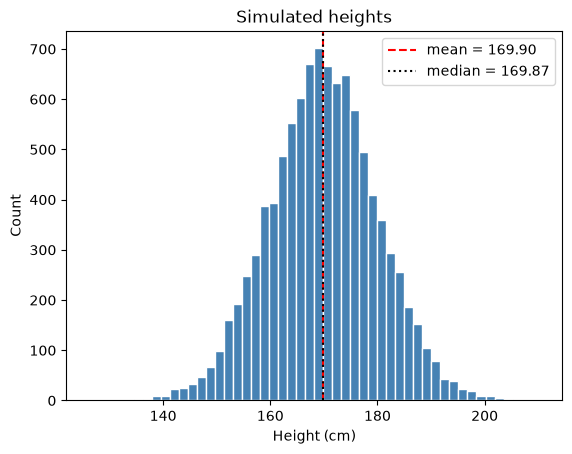

In [52]:
def plot_hist(data, title="", xlabel="Value", bins=50, ax=None, color="steelblue"):
    """Draw a histogram with the mean (red dashed) and median (black dotted) marked."""
    if ax is None:                        # if no axes were given, make a new figure
        fig, ax = plt.subplots()
    ax.hist(data, bins=bins, color=color, edgecolor="white")
    ax.axvline(np.mean(data), color="red", linestyle="--", label=f"mean = {np.mean(data):.2f}")
    ax.axvline(np.median(data), color="black", linestyle=":", label=f"median = {np.median(data):.2f}")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Count")
    ax.legend()
    return ax

plot_hist(heights, title="Simulated heights", xlabel="Height (cm)")
plt.show()

---
## Part 3: A Gallery of Common Distributions

Different processes in the world produce different shapes. Here are the ones you'll meet most often in social science.

| Distribution | Shape | What produces it | Real-world examples |
|---|---|---|---|
| **Uniform** | Flat | Every value in a range is equally likely | Rolling one die, random lottery numbers |
| **Normal** | Symmetric bell | *Adding* many small independent effects | Height, measurement error, test scores |
| **Lognormal** | Right-skewed, long tail | *Multiplying* many independent effects | Adult weight, income, city sizes, skill (Elo) |
| **Exponential** | Steep drop-off | Waiting time until a random event | Time between customer arrivals or website visits |
| **Pareto (power law)** | Extremely long tail | "Rich get richer" processes | Wealth at the very top, book sales, social media followers |
| **Binomial** | Counts, bell-ish | Number of successes in *n* yes/no trials | Number of heads in 20 coin flips |
| **Poisson** | Counts, right-skewed when small | Number of rare events in a fixed window | Emails per hour, accidents per day |

Let's simulate 10,000 values from each and look at them side by side.

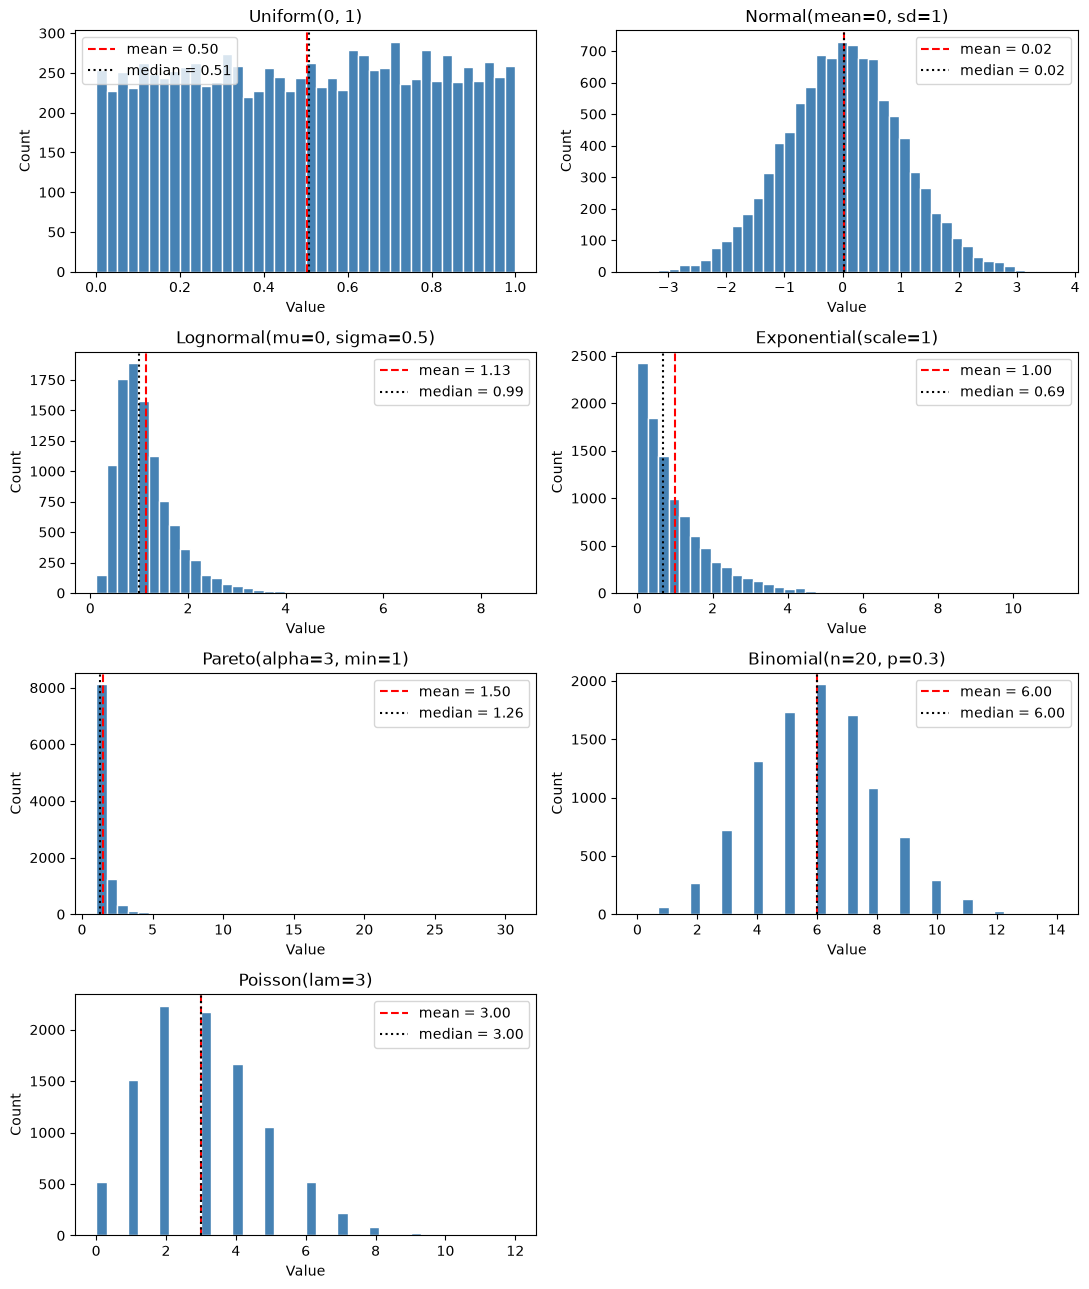

In [53]:
n = 10_000

samples = {
    "Uniform(0, 1)":            rng.uniform(low=0, high=1, size=n),
    "Normal(mean=0, sd=1)":     rng.normal(loc=0, scale=1, size=n),
    "Lognormal(mu=0, sigma=0.5)": rng.lognormal(mean=0, sigma=0.5, size=n),
    "Exponential(scale=1)":     rng.exponential(scale=1, size=n),
    "Pareto(alpha=3, min=1)":   (rng.pareto(a=3, size=n) + 1),   # +1 gives the classic Pareto with minimum 1
    "Binomial(n=20, p=0.3)":    rng.binomial(n=20, p=0.3, size=n),
    "Poisson(lam=3)":           rng.poisson(lam=3, size=n),
}

# Make a grid of 4 rows x 2 columns of small plots
fig, axes = plt.subplots(4, 2, figsize=(11, 13))
axes = axes.flatten()   # turn the 4x2 grid into a simple list of 8 axes

for ax, (name, data) in zip(axes, samples.items()):
    plot_hist(data, title=name, ax=ax, bins=40)

axes[-1].axis("off")    # we only have 7 distributions, so hide the 8th panel
plt.tight_layout()
plt.show()

### 3.1 Reading the gallery

Look at where the **mean (red)** and **median (black)** sit in each panel:

- **Symmetric** distributions (uniform, normal): mean ≈ median.
- **Right-skewed** distributions (lognormal, exponential, Pareto): the mean is pulled to the **right** of the median, toward the long tail. A few very large values drag the mean up, but they barely move the median.
- **Count** distributions (binomial, Poisson) only take whole numbers, so the median lands exactly on a whole number. The Poisson here is mildly right-skewed (look at its tail), even though its mean and median happen to match.

We can measure this lopsidedness with a number called **skewness**:

- skewness ≈ 0 → symmetric
- skewness > 0 → long tail to the right
- skewness < 0 → long tail to the left

Let's compute a summary table using `pandas`.

In [54]:
rows = []
for name, data in samples.items():
    rows.append({
        "distribution": name,
        "mean": np.mean(data),
        "median": np.median(data),
        "std": np.std(data),
        "skewness": stats.skew(data),
        "max": np.max(data),
    })

summary = pd.DataFrame(rows).set_index("distribution")
summary.round(2)

,mean,median,std,skewness,max
distribution,,,,,
"Uniform(0, 1)",0.50,0.51,0.29,-0.02,1.00
"Normal(mean=0, sd=1)",0.02,0.02,1.00,0.02,3.68
"Lognormal(mu=0, sigma=0.5)",1.13,0.99,0.61,1.88,8.70
Exponential(scale=1),1.00,0.69,0.98,1.96,11.16
"Pareto(alpha=3, min=1)",1.50,1.26,0.87,9.56,30.70
"Binomial(n=20, p=0.3)",6.00,6.00,2.03,0.19,14.00
Poisson(lam=3),3.00,3.00,1.75,0.57,12.00


Notice that the **Pareto** distribution has the largest skewness and the most extreme maximum. Pareto tails are even heavier than lognormal tails. The lecture mentioned that incomes at the very highest levels have "many more than a log-normal would indicate"; that extra-heavy top tail is often modeled with a Pareto distribution.

## Part 4: CDFs, the Plots Used in the Lecture

Histograms are intuitive, but their shape depends on how many bins you choose. Let's look at a different kind of plot: the **CDF** (cumulative distribution function).

For any value *x*, the CDF tells you **what fraction of the data is less than or equal to *x***. We'll show it as a *percentile rank* from 0 to 100.

- The CDF always rises from 0 to 100.
- Where the curve is **steep**, lots of data is packed in.
- A long, slow approach to 100 on the right means a **long right tail**.

The *empirical* CDF (ECDF) is computed straight from data: sort the values, and give each one its rank.

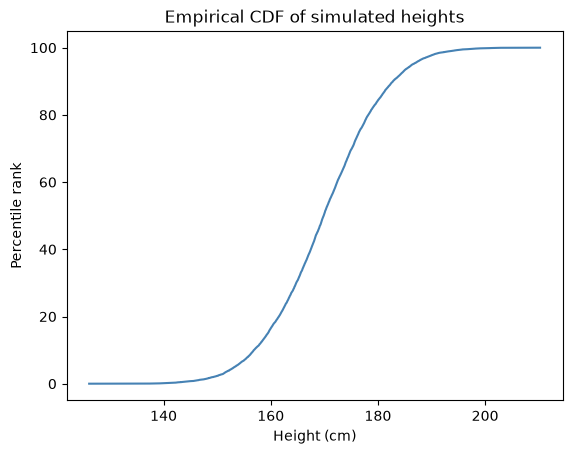

In [55]:
def ecdf(data):
    """Return (sorted values, percentile ranks) for plotting an empirical CDF."""
    x = np.sort(data)
    y = np.arange(1, len(x) + 1) / len(x) * 100   # 1/n, 2/n, ..., n/n as percentages
    return x, y

x, y = ecdf(heights)
plt.plot(x, y, color="steelblue")
plt.xlabel("Height (cm)")
plt.ylabel("Percentile rank")
plt.title("Empirical CDF of simulated heights")
plt.show()

### 4.1 Comparing data to a model

The real power of CDFs is comparing data to a **model**. Here's the recipe Downey uses in the lecture:

1. Compute the mean and standard deviation of the data.
2. Build a normal distribution with that same mean and SD.
3. Plot the model's CDF (grey) behind the data's CDF. If they overlap, the model fits.

`stats.norm.cdf(x, loc, scale)` gives the normal model's CDF at each `x`.

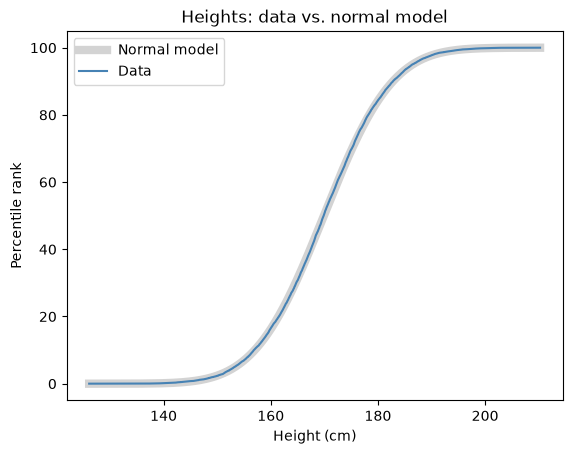

In [56]:
def compare_to_normal(data, xlabel="Value", title="", ax=None):
    """Plot the data's ECDF against a normal model with the same mean and SD."""
    if ax is None:
        fig, ax = plt.subplots()
    x, y = ecdf(data)
    
    model = stats.norm.cdf(x, loc=np.mean(data), scale=np.std(data)) * 100
    
    ax.plot(x, model, color="lightgray", linewidth=6, label="Normal model")
    ax.plot(x, y, color="steelblue", label="Data")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Percentile rank")
    ax.set_title(title)
    ax.legend()
    return ax

compare_to_normal(heights, xlabel="Height (cm)", title="Heights: data vs. normal model")
plt.show()

The data sits right on top of the model. Heights are well described by a normal distribution, just like the lecture said.

## Part 5: Simulating Distributions to Explain the World

Now for the fun part. Instead of just *drawing* from a distribution, we'll **simulate a process** and watch a distribution *emerge*. This is exactly the "verify with a simulation" step from the lecture.

### 5.1 Adding things up → Normal (the Central Limit Theorem)

Roll one die: every face 1–6 is equally likely (uniform). But what if you roll **10 dice and add them up**? Let's simulate 10,000 people each doing that.

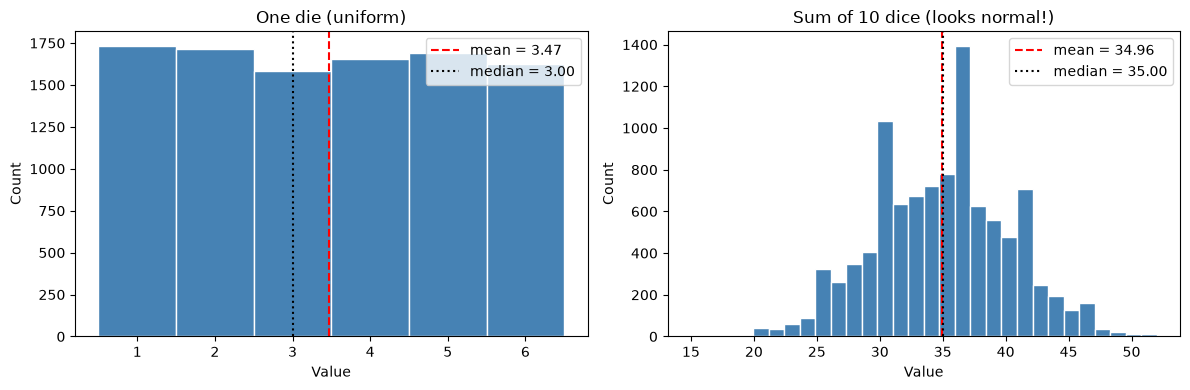

In [57]:
# rng.integers(1, 7) gives whole numbers from 1 to 6 (the 7 is NOT included).
# size=(10_000, 10) makes a table: 10,000 rows (people) x 10 columns (dice).
dice = rng.integers(1, 7, size=(10_000, 10))

one_die = dice[:, 0]              # just the first column
sum_of_ten = dice.sum(axis=1)     # add across each row

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_hist(one_die, title="One die (uniform)", bins=np.arange(0.5, 7.5, 1), ax=axes[0])
plot_hist(sum_of_ten, title="Sum of 10 dice (looks normal!)", bins=30, ax=axes[1])
plt.tight_layout()
plt.show()

Even though each die is flat, their **sum** is bell-shaped. This is the **Central Limit Theorem**: adding up many independent random pieces tends to produce a normal distribution, no matter what the pieces look like.

### 5.2 Multiplying things → Lognormal

Now let's **multiply** instead of add. Each person gets 10 random "factors," each between 0.5 and 1.5, and we multiply them together.

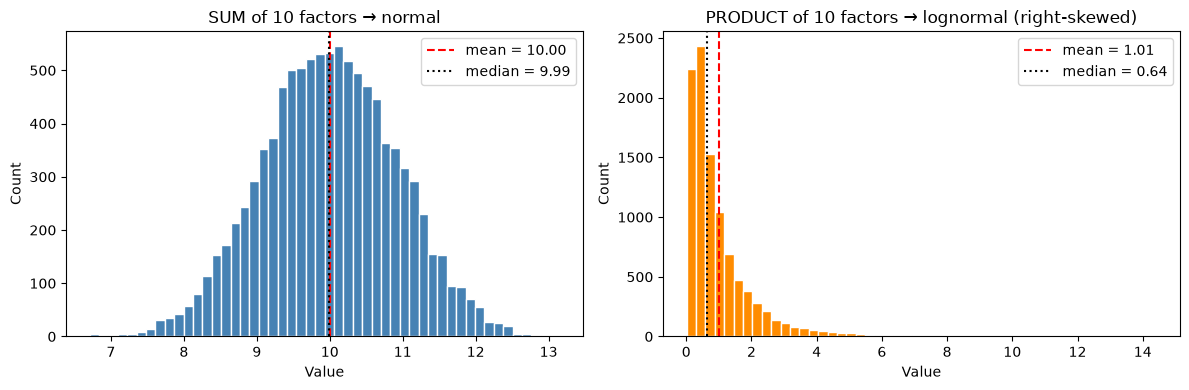

Skewness of sums:     -0.02
Skewness of products: 3.09


In [58]:
factors = rng.uniform(0.5, 1.5, size=(10_000, 10))

sums = factors.sum(axis=1)        # add the 10 factors
products = factors.prod(axis=1)   # multiply the 10 factors

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_hist(sums, title="SUM of 10 factors → normal", ax=axes[0])
plot_hist(products, title="PRODUCT of 10 factors → lognormal (right-skewed)", ax=axes[1], color="darkorange")
plt.tight_layout()
plt.show()

print(f"Skewness of sums:     {stats.skew(sums):.2f}")
print(f"Skewness of products: {stats.skew(products):.2f}")

Same ingredients, different recipe, completely different shape! The product has a long right tail: a few lucky people got many factors above 1, and multiplication **amplifies** that luck. 

Why does multiplying give a *lognormal* specifically? Because of this rule of logarithms:

$$\log(Y_1 \times Y_2 \times \cdots \times Y_N) = \log(Y_1) + \log(Y_2) + \cdots + \log(Y_N)$$

The log of a product is a **sum**, and sums are normal (Central Limit Theorem). So the **log** of the product is normal, which is the definition of lognormal. Let's check:

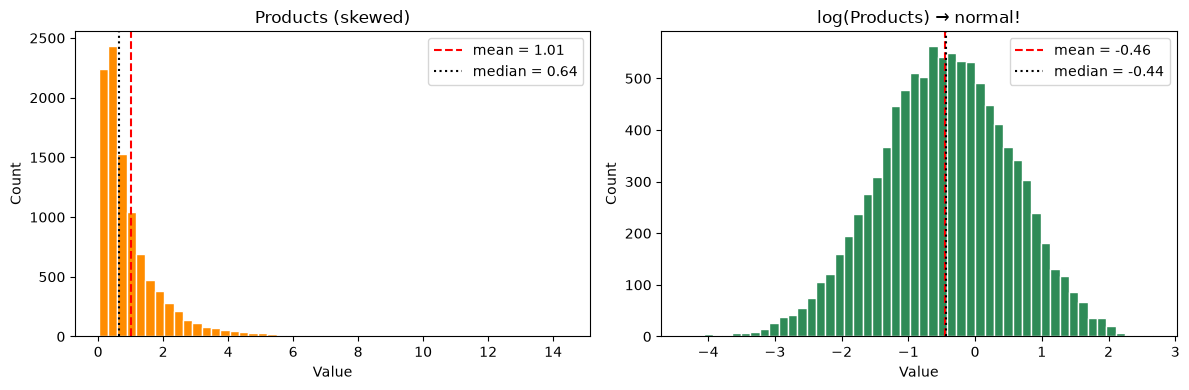

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_hist(products, title="Products (skewed)", ax=axes[0], color="darkorange")
plot_hist(np.log(products), title="log(Products) → normal!", ax=axes[1], color="seagreen")
plt.tight_layout()
plt.show()

### 5.3 Case study: Why are adult weights lognormal? (Lecture slides 11–14)

The lecture's puzzle: **birth weights are normal, but adult weights are lognormal.** The proposed explanation: each year, people gain a **percentage** of their current weight, not a fixed number of kilograms.

Let's simulate both stories and compare.

- **Additive story:** every year, add a random number of kilograms.
- **Multiplicative story:** every year, multiply by a random growth factor (like +8% ± 4%).

Both start from normally distributed birth weights (mean 3.4 kg, SD 0.5 kg) and run for 40 years. The parameters are illustrative choices that land adults near 80 kg, not values fitted to real data.

In [60]:
n_people = 10_000
n_years = 40

birth_weights = rng.normal(loc=3.4, scale=0.5, size=n_people)

# --- Additive story: add ~1.9 kg per year (give or take 1.4 kg) ---
yearly_gain_kg = rng.normal(loc=1.9, scale=1.4, size=(n_people, n_years))
adult_additive = birth_weights + yearly_gain_kg.sum(axis=1)

# --- Multiplicative story: grow by ~8% per year (give or take 4%) ---
yearly_growth = rng.normal(loc=0.08, scale=0.04, size=(n_people, n_years))
adult_multiplicative = birth_weights * (1 + yearly_growth).prod(axis=1)

print(f"Additive:       mean = {adult_additive.mean():.1f} kg, skewness = {stats.skew(adult_additive):.2f}")
print(f"Multiplicative: mean = {adult_multiplicative.mean():.1f} kg, skewness = {stats.skew(adult_multiplicative):.2f}")

Additive:       mean = 79.3 kg, skewness = -0.01
Multiplicative: mean = 74.0 kg, skewness = 0.83


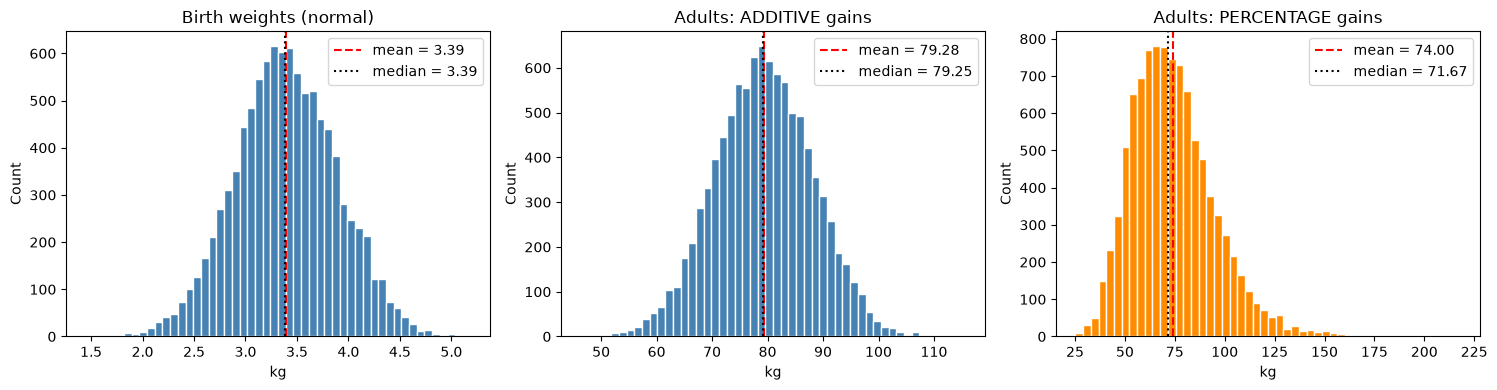

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_hist(birth_weights, title="Birth weights (normal)", xlabel="kg", ax=axes[0])
plot_hist(adult_additive, title="Adults: ADDITIVE gains", xlabel="kg", ax=axes[1])
plot_hist(adult_multiplicative, title="Adults: PERCENTAGE gains", xlabel="kg", ax=axes[2], color="darkorange")
plt.tight_layout()
plt.show()

The additive story keeps the bell shape. The multiplicative story produces the long right tail we see in real adult weights. That's the lecture's argument, reproduced in a few lines of code.

Now let's repeat the lecture's "log scale" check: does the multiplicative simulation look normal after we take the log?

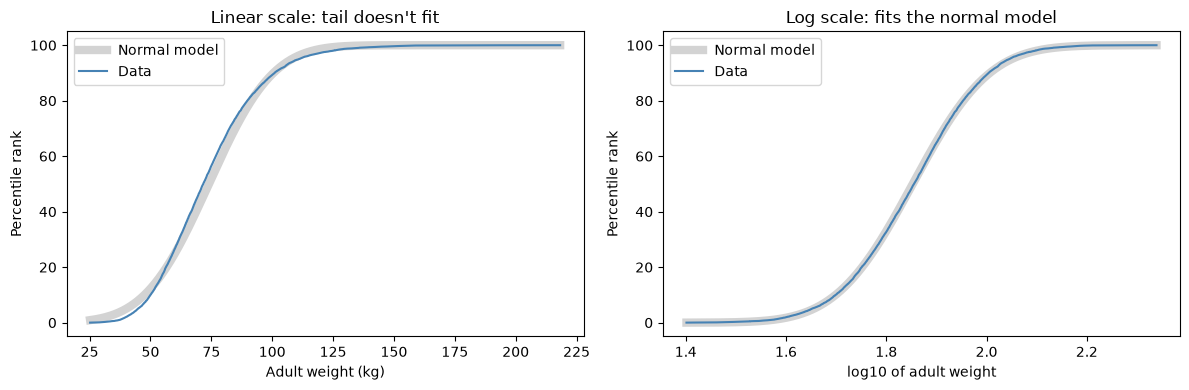

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
compare_to_normal(adult_multiplicative, xlabel="Adult weight (kg)", title="Linear scale: tail doesn't fit", ax=axes[0])
compare_to_normal(np.log10(adult_multiplicative), xlabel="log10 of adult weight", title="Log scale: fits the normal model", ax=axes[1])
plt.tight_layout()
plt.show()

Exactly the pattern from slides 8 and 9 of the lecture: a poor fit in the upper tail on the linear scale, a near-perfect fit on the log scale.

### 5.4 Case study: Percentage raises and income inequality (Lecture slides 18–20)

First, Amanda and Alice. They start at 60,000 and $50,000. Let's compare 20 years of **5\% raises** against 20 years of a **fixed 3,000 raise**. We'll use a `for` loop, which repeats the indented code once for each year.

In [63]:
years = 20
pct_raise = 0.05
fixed_raise = 3000

amanda_pct, alice_pct = 60000, 50000
amanda_fix, alice_fix = 60000, 50000

for year in range(years):           # repeats 20 times
    amanda_pct = amanda_pct * (1 + pct_raise)
    alice_pct  = alice_pct  * (1 + pct_raise)
    amanda_fix = amanda_fix + fixed_raise
    alice_fix  = alice_fix  + fixed_raise

print("After 20 years of 5% raises:")
print(f"  Alice ${alice_pct:,.0f}, Amanda ${amanda_pct:,.0f}, gap ${amanda_pct - alice_pct:,.0f}, ratio {alice_pct/amanda_pct:.1%}")
print("After 20 years of $3,000 raises:")
print(f"  Alice ${alice_fix:,.0f}, Amanda ${amanda_fix:,.0f}, gap ${amanda_fix - alice_fix:,.0f}, ratio {alice_fix/amanda_fix:.1%}")

After 20 years of 5% raises:
  Alice $132,665, Amanda $159,198, gap $26,533, ratio 83.3%
After 20 years of $3,000 raises:
  Alice $110,000, Amanda $120,000, gap $10,000, ratio 91.7%


With percentage raises, the **ratio** stays at 83%, but the **dollar gap** more than doubles. With fixed raises, the dollar gap stays at \$10,000, and Alice catches up in relative terms.

Now let's scale this up to a whole company: 5,000 employees who all start at similar salaries, then get a random raise (average 3%, give or take 3%) every year for 35 years.

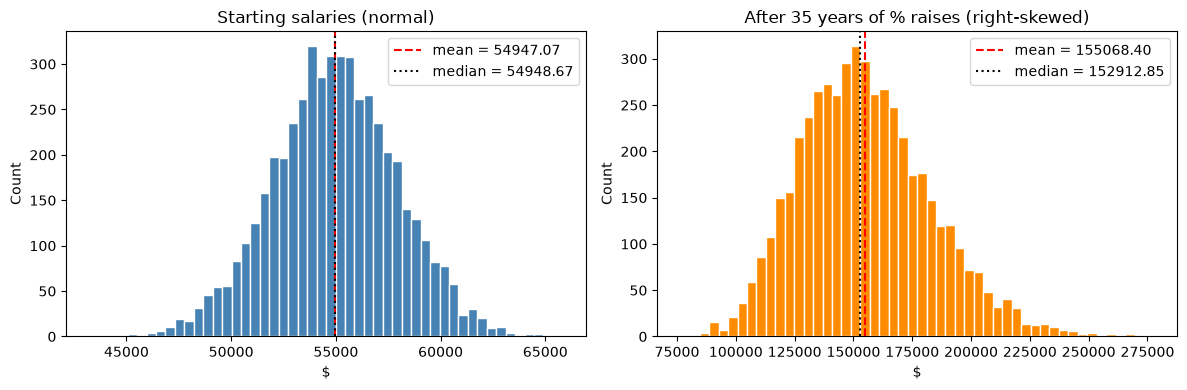

Start: 90th-10th percentile gap = $7,671,  skewness = -0.03
After: 90th-10th percentile gap = $70,682,  skewness = 0.47


In [64]:
n_employees = 5_000
n_years = 35

start = rng.normal(loc=55_000, scale=3_000, size=n_employees)
raises = rng.normal(loc=0.03, scale=0.03, size=(n_employees, n_years))

salary_after = start * (1 + raises).prod(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_hist(start, title="Starting salaries (normal)", xlabel="$", ax=axes[0])
plot_hist(salary_after, title="After 35 years of % raises (right-skewed)", xlabel="$", ax=axes[1], color="darkorange")
plt.tight_layout()
plt.show()

# Gap between the 90th and 10th percentile employee, in dollars
def p90_p10_gap(x):
    p10, p90 = np.percentile(x, [10, 90])
    return p90 - p10

print(f"Start: 90th-10th percentile gap = ${p90_p10_gap(start):,.0f},  skewness = {stats.skew(start):.2f}")
print(f"After: 90th-10th percentile gap = ${p90_p10_gap(salary_after):,.0f},  skewness = {stats.skew(salary_after):.2f}")

Nobody in this simulation is treated unfairly in any obvious way: everyone's raise comes from the same random rule. Yet the distribution becomes right-skewed, and the dollar gap between high and low earners grows many times over. **Multiplicative processes create inequality on their own.**

### 5.5 Case study: Weak links and running speed (Lecture slides 22–26)

The lecture argued that speed depends on several factors that **multiply**, so one weak factor drags everything down. Let's see the difference between adding and multiplying factors when one factor is weak.

In [65]:
strong = np.array([0.9, 0.9, 0.9, 0.9, 0.9])
one_weak = np.array([0.9, 0.9, 0.9, 0.9, 0.3])   # same, but the last factor is weak

print("Average of factors (additive view):")
print(f"  all strong: {strong.mean():.3f}   one weak: {one_weak.mean():.3f}   → drops by {1 - one_weak.mean()/strong.mean():.0%}")
print("Product of factors (multiplicative view):")
print(f"  all strong: {strong.prod():.3f}   one weak: {one_weak.prod():.3f}   → drops by {1 - one_weak.prod()/strong.prod():.0%}")

Average of factors (additive view):
  all strong: 0.900   one weak: 0.780   → drops by 13%
Product of factors (multiplicative view):
  all strong: 0.590   one weak: 0.197   → drops by 67%


Under the additive view, one weak factor costs about 13%. Under the multiplicative view, it costs about 67%. The product "depends on the smallest factor," just as the lecture said.

Now let's simulate a race. Like Downey's simulation of the James Joyce Ramble, each of 1,592 runners has **5 normally distributed factors** that multiply to give their speed. (The mean, SD, and base speed below are illustrative, not Downey's fitted values.)

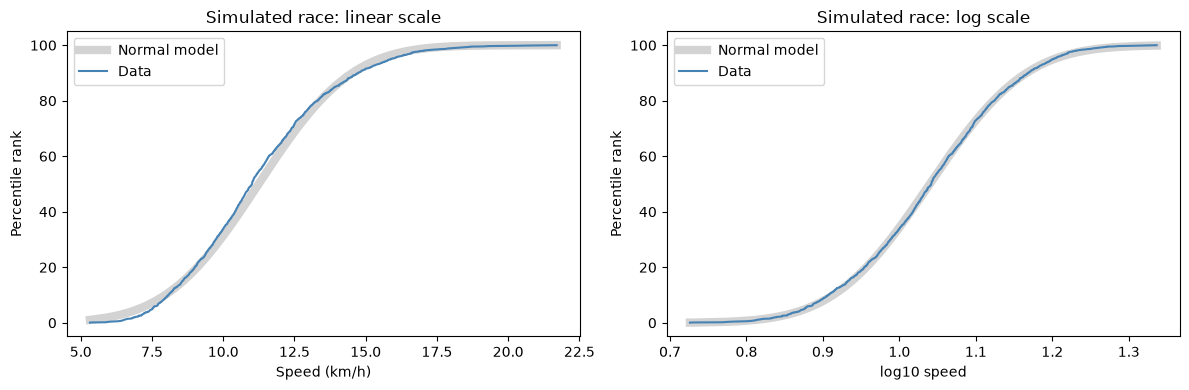

In [66]:
n_runners = 1592
runner_factors = rng.normal(loc=1.0, scale=0.1, size=(n_runners, 5))
speed_kph = 11 * runner_factors.prod(axis=1)   # 11 km/h is a typical recreational pace

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
compare_to_normal(speed_kph, xlabel="Speed (km/h)", title="Simulated race: linear scale", ax=axes[0])
compare_to_normal(np.log10(speed_kph), xlabel="log10 speed", title="Simulated race: log scale", ax=axes[1])
plt.tight_layout()
plt.show()

With small factor variation (SD 0.1), the difference between normal and lognormal is subtle on the linear scale, which is also what the real race data on slide 25 looked like. The log scale gives the tighter fit.

### 5.6 Case study: Why GOATs exist (Lecture slides 35–36)

We'll create two populations of chess players with the **same mean and the same standard deviation**:

- one **normal**
- one **lognormal**

Then we'll ask: how often does the **#1 player beat the #3 player**? Chess uses the Elo formula, where a rating difference *d* gives the higher-rated player a win probability of

$$P(\text{win}) = \frac{1}{1 + 10^{-d/400}}$$

In [67]:
def elo_win_prob(rating_diff):
    """Probability that the higher-rated player wins, given the rating difference."""
    return 1 / (1 + 10 ** (-rating_diff / 400))

print(f"400-point gap: {elo_win_prob(400):.0%} chance of winning")   # the lecture's "about 90%"
print(f"100-point gap: {elo_win_prob(100):.0%} chance of winning")

400-point gap: 91% chance of winning
100-point gap: 64% chance of winning


In [68]:
n_players = 10_000

# Lognormal skill: median rating ~600, sigma 0.4 on the log scale
lognormal_skill = rng.lognormal(mean=np.log(600), sigma=0.4, size=n_players)

# Normal skill with the SAME mean and SD as the lognormal population
normal_skill = rng.normal(loc=lognormal_skill.mean(), scale=lognormal_skill.std(), size=n_players)

print(f"Normal:    mean {normal_skill.mean():.0f}, SD {normal_skill.std():.0f}")
print(f"Lognormal: mean {lognormal_skill.mean():.0f}, SD {lognormal_skill.std():.0f}")

top3_normal = np.sort(normal_skill)[-3:]        # the three largest values
top3_lognormal = np.sort(lognormal_skill)[-3:]
print("Top 3 (normal):   ", top3_normal.round())
print("Top 3 (lognormal):", top3_lognormal.round())

Normal:    mean 650, SD 266
Lognormal: mean 651, SD 268
Top 3 (normal):    [1548. 1556. 1560.]
Top 3 (lognormal): [2433. 2498. 2559.]


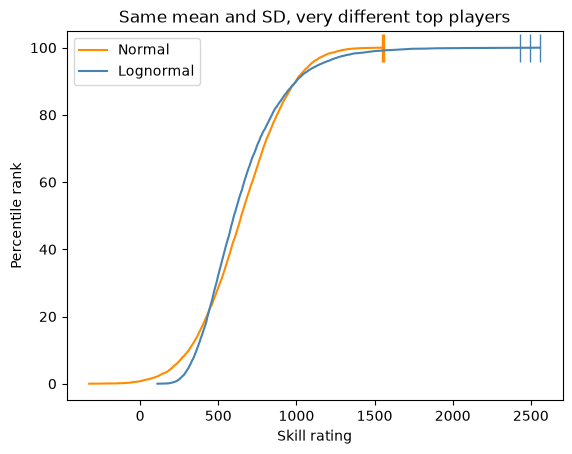

In [69]:
fig, ax = plt.subplots()
for data, name, color in [(normal_skill, "Normal", "darkorange"), (lognormal_skill, "Lognormal", "steelblue")]:
    x, y = ecdf(data)
    ax.plot(x, y, label=name, color=color)
    ax.plot(np.sort(data)[-3:], [100, 100, 100], "|", markersize=20, color=color)   # tick marks at the top 3
ax.set_xlabel("Skill rating")
ax.set_ylabel("Percentile rank")
ax.set_title("Same mean and SD, very different top players")
ax.legend()
plt.show()

A single simulation could be lucky, so let's repeat the experiment **500 times** and average the win probability of #1 over #3.

In [70]:
n_trials = 500
p_normal, p_lognormal = [], []      # empty lists to collect results

for trial in range(n_trials):
    L = rng.lognormal(mean=np.log(600), sigma=0.4, size=n_players)
    N = rng.normal(loc=L.mean(), scale=L.std(), size=n_players)
    for data, results in [(N, p_normal), (L, p_lognormal)]:
        top3 = np.sort(data)[-3:]
        results.append(elo_win_prob(top3[2] - top3[0]))   # #1 minus #3

print(f"Normal world:    #1 beats #3 about {np.mean(p_normal):.0%} of the time")
print(f"Lognormal world: #1 beats #3 about {np.mean(p_lognormal):.0%} of the time")

Normal world:    #1 beats #3 about 64% of the time
Lognormal world: #1 beats #3 about 84% of the time


In the normal world, the top player is only modestly better than #3, so championships rotate. In the lognormal world, the top player is **dominant**. The lecture's simulation found about 55% versus 80%; your exact numbers depend on the parameters, but the gap between the two worlds is the point. **Long tails produce GOATs.**


## Part 6: The Log Transformation

You've already seen the log transformation in action. Let's now treat it as a tool you can use on any data.

### 6.1 What does a logarithm do?

`log10(x)` asks: "10 to what power gives *x*?"

| x | 1 | 10 | 100 | 1,000 | 10,000 |
|---|---|---|---|---|---|
| log10(x) | 0 | 1 | 2 | 3 | 4 |

The log turns **multiplying by 10** into **adding 1**. It squashes big numbers much more than small ones, which pulls a long right tail back toward the middle.

NumPy has three logs you'll see:

- `np.log10(x)`: base 10, easy to read ("2 means hundreds, 3 means thousands")
- `np.log(x)`: natural log (base *e* ≈ 2.718), common in statistics
- `np.log1p(x)`: computes log(1 + x), safe when your data contains **zeros**

The *base* doesn't change the shape of the result, only the units.

In [71]:
values = np.array([1, 10, 100, 1000, 10000])
print("log10:", np.log10(values))
print("ln:   ", np.log(values).round(2))

log10: [0. 1. 2. 3. 4.]
ln:    [0.   2.3  4.61 6.91 9.21]


### 6.2 Before and after: transforming skewed data

Let's take the simulated salaries from Part 5.4 and log-transform them.

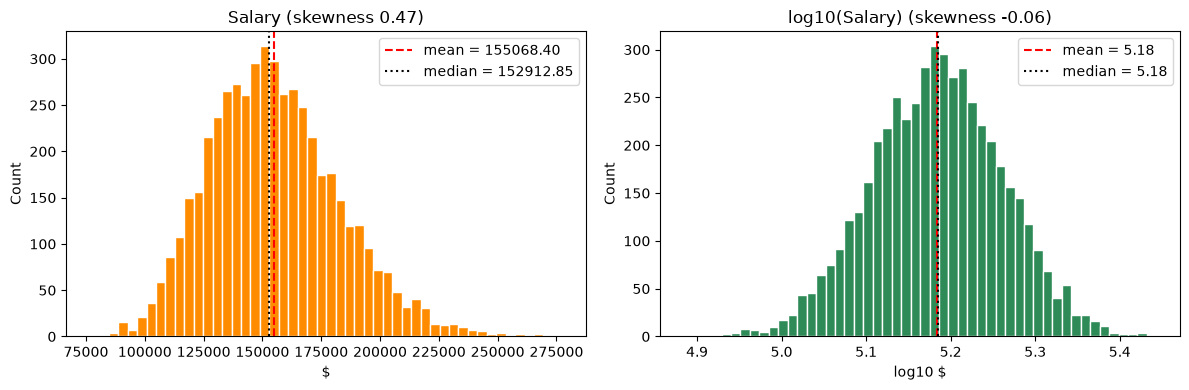

In [72]:
log_salary = np.log10(salary_after)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_hist(salary_after, title=f"Salary (skewness {stats.skew(salary_after):.2f})", xlabel="$", ax=axes[0], color="darkorange")
plot_hist(log_salary, title=f"log10(Salary) (skewness {stats.skew(log_salary):.2f})", xlabel="log10 $", ax=axes[1], color="seagreen")
plt.tight_layout()
plt.show()

Skewness drops to nearly zero, and the mean and median line up. The transformed data is much easier to work with: many statistical methods (like averages, t-tests, linear regression) behave better when data is roughly symmetric.

### 6.3 An alternative: keep the data, change the axis

Sometimes you don't want to change your numbers, just *see* them better. You can put the axis on a log scale instead. The tick labels stay in real dollars.

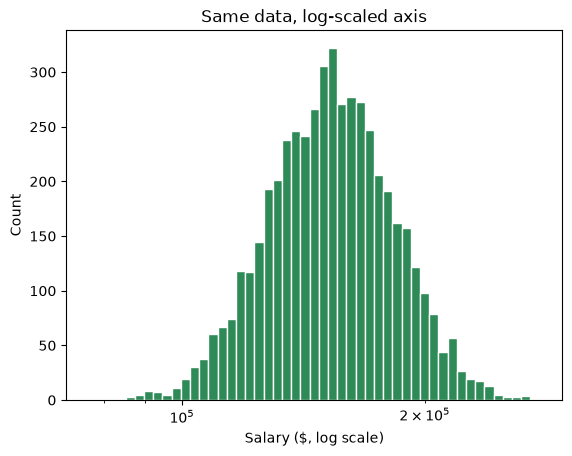

In [73]:
fig, ax = plt.subplots()
bins = np.logspace(np.log10(salary_after.min()), np.log10(salary_after.max()), 50)  # evenly spaced on a log scale
ax.hist(salary_after, bins=bins, color="seagreen", edgecolor="white")
ax.set_xscale("log")
ax.set_xlabel("Salary ($, log scale)")
ax.set_ylabel("Count")
ax.set_title("Same data, log-scaled axis")
plt.show()

### 6.4 Checking normality with a Q-Q plot

A **Q-Q plot** (quantile-quantile plot) is the standard tool for asking "is this normal?" It plots your data's quantiles against what a perfect normal distribution would give.

- Points on the **straight line** → normal.
- Points curving **up at the right end** → a long right tail (right skew).

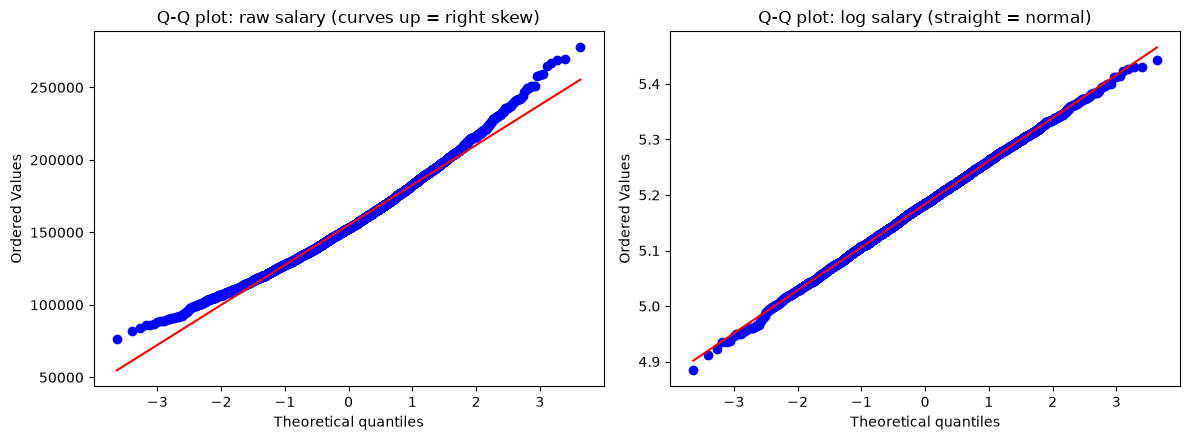

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
stats.probplot(salary_after, dist="norm", plot=axes[0])
axes[0].set_title("Q-Q plot: raw salary (curves up = right skew)")
stats.probplot(log_salary, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot: log salary (straight = normal)")
plt.tight_layout()
plt.show()

### 6.5 Going back: interpreting log results

If you average log values, you must convert back with the **inverse** of the log: `10 ** value` for log10, or `np.exp(value)` for the natural log. The result is called the **geometric mean**, and for lognormal data it is close to the median, a better "typical value" than the ordinary mean.

In [75]:
arith_mean = salary_after.mean()
geo_mean = 10 ** log_salary.mean()      # undo log10
median = np.median(salary_after)

print(f"Arithmetic mean: ${arith_mean:,.0f}")
print(f"Geometric mean:  ${geo_mean:,.0f}")
print(f"Median:          ${median:,.0f}")

Arithmetic mean: $155,068
Geometric mean:  $152,628
Median:          $152,913


### 6.6 Cautions

- **The log of zero or a negative number is undefined.** `np.log(0)` gives `-inf` and `np.log(-5)` gives `nan` (not a number). For counts with zeros, use `np.log1p(x)`.
- **Log doesn't fix everything.** It helps *right-skewed, positive* data. It will make symmetric data left-skewed, and it can't fix data that is skewed to the left.
- **Log changes the meaning** of differences: on a log scale, equal distances mean equal *ratios*. A one-unit change in log10(salary) means "10 times as much," not "\$1 more."

In [76]:
# What happens with zeros?
counts = np.array([0, 1, 3, 10, 50])
with np.errstate(divide="ignore"):            # silence the warning so we can see the result
    print("np.log:  ", np.log(counts))
print("np.log1p:", np.log1p(counts).round(2))

np.log:   [      -inf 0.         1.09861229 2.30258509 3.91202301]
np.log1p: [0.   0.69 1.39 2.4  3.93]



## Part 7: Scaling and Normalization

### 7.1 Why scale?

Suppose we describe people by **age** (roughly 20–65) and **salary** (roughly \$30,000–\$200,000). If we compare two people by "how different are they?", salary dominates completely because its numbers are thousands of times bigger. Scaling puts variables on a **common scale** so they can be compared fairly. Many machine learning methods (k-nearest neighbors, k-means clustering, neural networks, regularized regression) require it.

### 7.2 Words people use (they're confusing!)

| Name | Formula | Result | Sensitive to outliers? |
|---|---|---|---|
| **Min-max scaling** (often called "normalization") | (x − min) / (max − min) | Values between 0 and 1 | **Very** |
| **Standardization** (z-scores) | (x − mean) / SD | Mean 0, SD 1 | Somewhat |
| **Robust scaling** | (x − median) / IQR | Median 0, IQR 1 | **Barely** |

**Important:** in everyday data science, "normalization" usually means min-max scaling. It does **not** make your data normally distributed! None of these three methods changes the **shape** of the distribution; they only shift and stretch it. Only a nonlinear transformation like the **log** changes shape.

Let's build a small dataset with pandas.

In [77]:
n = 500
people = pd.DataFrame({
    "age": rng.integers(22, 66, size=n),
    "salary": rng.lognormal(mean=np.log(60_000), sigma=0.45, size=n).round(-2),   # round to nearest $100
})

people.head()      # .head() shows the first 5 rows

,age,salary
0,28,179000.0
1,58,67900.0
2,45,85400.0
3,23,140600.0
4,26,54900.0


In [78]:
people.describe().round(1)    # summary statistics for every column

,age,salary
count,500.0,500.0
mean,42.6,67444.6
std,12.6,32880.8
min,22.0,17400.0
25%,32.0,44850.0
50%,41.5,59850.0
75%,54.0,82375.0
max,65.0,210700.0


### 7.3 Min-max scaling

In [79]:
def min_max_scale(x):
    """Rescale values to the range [0, 1]."""
    return (x - x.min()) / (x.max() - x.min())

people["salary_minmax"] = min_max_scale(people["salary"])
people["age_minmax"] = min_max_scale(people["age"])

people[["age", "age_minmax", "salary", "salary_minmax"]].head()

,age,age_minmax,salary,salary_minmax
0,28,0.139535,179000.0,0.836006
1,58,0.837209,67900.0,0.261252
2,45,0.534884,85400.0,0.351785
3,23,0.023256,140600.0,0.637351
4,26,0.093023,54900.0,0.193999


### 7.4 Standardization (z-scores)

A **z-score** tells you how many standard deviations a value is above (+) or below (−) the mean. A z-score of 2 means "2 SDs above average."

In [80]:
def z_score(x):
    """Standardize values to mean 0 and standard deviation 1."""
    return (x - x.mean()) / x.std()

people["salary_z"] = z_score(people["salary"])
people["age_z"] = z_score(people["age"])

print("Mean of salary_z:", round(people["salary_z"].mean(), 4))
print("SD of salary_z:  ", round(people["salary_z"].std(), 4))

Mean of salary_z: -0.0
SD of salary_z:   1.0


### 7.5 Scaling changes the numbers, not the shape

Here's the proof. All three scaled versions have exactly the same histogram shape as the original; only the numbers on the x-axis change.

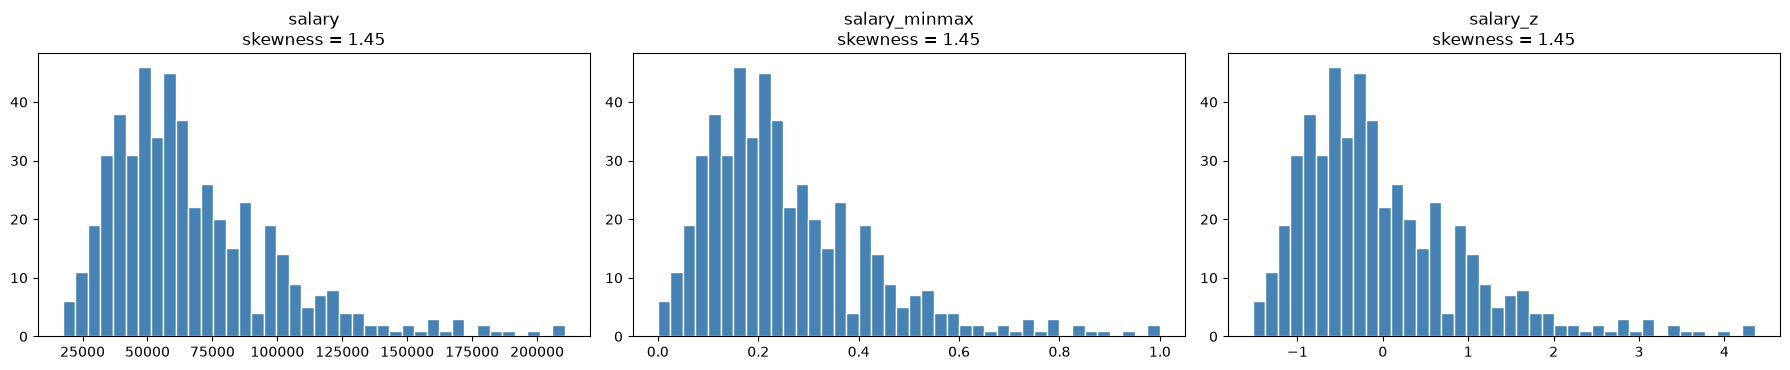

In [84]:
fig, axes = plt.subplots(1, 3, figsize=(18, 3.8))
cols = ["salary", "salary_minmax", "salary_z"]
for ax, col in zip(axes, cols):
    ax.hist(people[col], bins=40, color="steelblue", edgecolor="white")
    ax.set_title(f"{col}\nskewness = {stats.skew(people[col]):.2f}")
plt.tight_layout()
plt.show()

The skewness is identical in all four panels. If you want to **reduce skew**, transform first (for example, with a log), *then* scale:

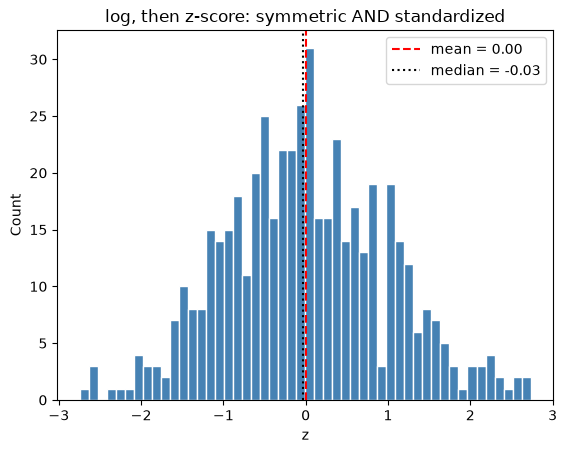

In [85]:
people["log_salary_z"] = z_score(np.log10(people["salary"]))

plot_hist(people["log_salary_z"], title="log, then z-score: symmetric AND standardized", xlabel="z")
plt.show()

In [86]:
salaries = people["salary"].copy()
salaries_with_error = pd.concat([salaries, pd.Series([5_000_000])], ignore_index=True)

methods = {"Min-max": min_max_scale, "Z-score": z_score, "Robust": robust_scale}

fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), sharey="row")
for col, (name, func) in enumerate(methods.items()):
    axes[0, col].hist(func(salaries), bins=40, color="steelblue", edgecolor="white")
    axes[0, col].set_title(f"{name}: clean data")
    scaled = func(salaries_with_error)[:-1]   # scale WITH the error, then look at everyone except the error
    axes[1, col].hist(scaled, bins=40, color="firebrick", edgecolor="white")
    axes[1, col].set_title(f"{name}: after adding ONE $5M error")
plt.tight_layout()
plt.show()

NameError: name 'robust_scale' is not defined

Look at the x-axis ranges in the bottom row:

- **Min-max:** the error becomes the new maximum (1.0), so all 500 real people get crushed into a tiny sliver near 0.
- **Z-score:** the error inflates the mean and SD, shifting and squeezing everyone else.
- **Robust:** barely changes at all, because the median and IQR ignore one extreme value.

**Rule of thumb:** if your data may contain outliers, use **robust scaling**, or deal with the outliers first.



## Part 8: Identifying Outliers

An **outlier** is a value that is unusually far from the rest of the data. Outliers come in two very different flavors:

1. **Errors:** typos, broken sensors, wrong units (a weight of 8,000 kg, an age of −3). These should be **fixed or removed**.
2. **Genuine extremes:** Robert Wadlow, Usain Bolt, a billionaire. These are **real** and often the most interesting part of the data. Deleting them can hide exactly the phenomenon you're studying (remember the GOATs!).

Statistics can **flag** unusual values, but only **you**, thinking about the context, can decide which flavor each one is.

We'll learn three detection rules and test them on two datasets: normal data and lognormal data, each with three planted errors.

In [87]:
# Dataset A: normally distributed heights + 3 data-entry errors
heights_clean = rng.normal(loc=170, scale=10, size=1000)
heights_errors = np.array([17.2, 1700, 250])     # forgot a digit, extra zero, impossible height
heights_A = np.concatenate([heights_clean, heights_errors])

# Dataset B: lognormal adult weights + 3 data-entry errors
weights_clean = rng.lognormal(mean=np.log(80), sigma=0.22, size=1000)
weights_errors = np.array([-75, 0, 8000])        # negative, zero, extra zeros
weights_B = np.concatenate([weights_clean, weights_errors])

print(f"Dataset A: {len(heights_A)} heights;  Dataset B: {len(weights_B)} weights")

Dataset A: 1003 heights;  Dataset B: 1003 weights


### 8.1 Look first: box plots

A **box plot** is designed for spotting outliers.

- The **box** spans Q1 to Q3 (the middle 50%), with a line at the median.
- The **whiskers** extend to the most extreme points within 1.5 × IQR of the box.
- Points beyond the whiskers are drawn individually as **possible outliers**.

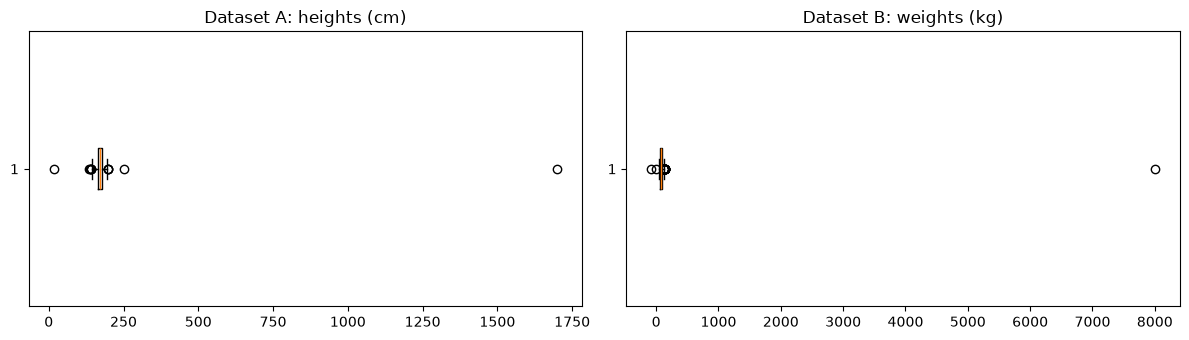

In [90]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].boxplot(heights_A, orientation='horizontal')
axes[0].set_title("Dataset A: heights (cm)")
axes[1].boxplot(weights_B, orientation='horizontal')
axes[1].set_title("Dataset B: weights (kg)")
plt.tight_layout()
plt.show()

The errors are so extreme that they squash everything else. That's actually a useful first lesson: **always plot your data before analyzing it**. Let's look again with the obvious errors removed, so we can see the shape.

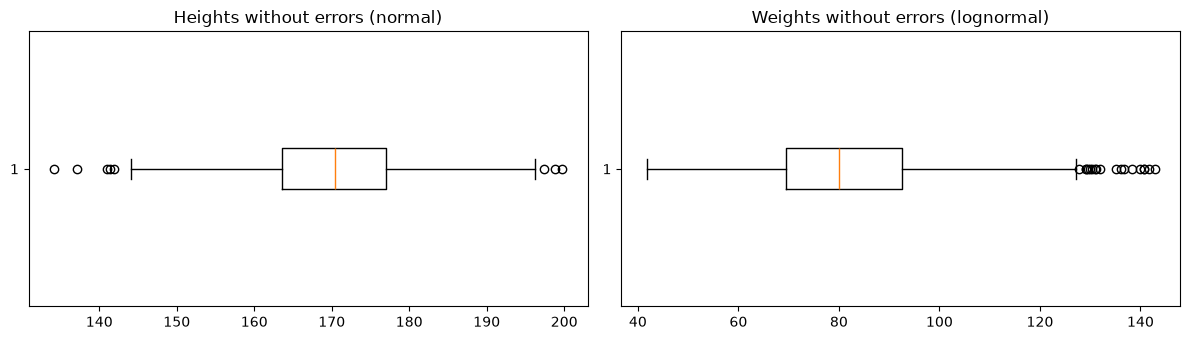

In [98]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].boxplot(heights_clean, orientation='horizontal')
axes[0].set_title("Heights without errors (normal)")
axes[1].boxplot(weights_clean, orientation='horizontal')
axes[1].set_title("Weights without errors (lognormal)")
plt.tight_layout()
plt.show()

Notice that even the **clean** lognormal weights show many points flagged on the right. Those aren't errors; they're the natural long tail. Keep that in mind.

### 8.2 Rule 1: The z-score rule

Flag any value more than **3 standard deviations** from the mean (|z| > 3). For truly normal data, only about 0.3% of values would be flagged by chance.

In [92]:
def outliers_zscore(x, threshold=3):
    """Return True for values whose |z-score| exceeds the threshold."""
    z = (x - np.mean(x)) / np.std(x)
    return np.abs(z) > threshold

flags = outliers_zscore(heights_A)
print("Number flagged:", flags.sum())
print("Flagged values:", np.sort(heights_A[flags]).round(1))

Number flagged: 2
Flagged values: [  17.2 1700. ]


Wait: the z-score rule caught the 1,700 cm error, but **missed** the 17.2 cm and 250 cm errors! Why?

The huge 1,700 value inflated the standard deviation so much that the other errors no longer look "far" in SD units. This is called **masking**: one big outlier hides the others. The mean and SD are themselves sensitive to outliers, so a rule built on them is fragile.

In [93]:
print(f"SD of clean heights:     {np.std(heights_clean):.1f} cm")
print(f"SD with the errors added: {np.std(heights_A):.1f} cm")

SD of clean heights:     10.1 cm
SD with the errors added: 49.6 cm


### 8.3 Rule 2: The IQR rule (Tukey's fences)

This is the rule box plots use. Flag any value below **Q1 − 1.5 × IQR** or above **Q3 + 1.5 × IQR**. Because quartiles ignore extremes, this rule doesn't suffer from masking.

In [94]:
def outliers_iqr(x, k=1.5):
    """Return True for values outside Tukey's fences: [Q1 - k*IQR, Q3 + k*IQR]."""
    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1
    lower, upper = q1 - k * iqr, q3 + k * iqr
    return (x < lower) | (x > upper)       # "|" means OR

flags = outliers_iqr(heights_A)
print("Number flagged:", flags.sum())
print("Flagged values:", np.sort(heights_A[flags]).round(1))

Number flagged: 11
Flagged values: [  17.2  134.2  137.1  141.   141.3  141.9  197.4  198.8  199.7  250.
 1700. ]


All three errors are caught now. It also flags a few genuine (but unusual) heights near the edges; that's normal. A rule flags *candidates*; you still inspect them.

### 8.4 Rule 3: The modified z-score (median and MAD)

This is a robust version of the z-score. It replaces the mean with the **median**, and the SD with the **MAD** (median absolute deviation: the median distance of points from the median). A common cutoff is a modified z-score above **3.5**.

$$\text{modified } z = 0.6745 \times \frac{x - \text{median}}{\text{MAD}}$$

(The 0.6745 just makes the result comparable to ordinary z-scores for normal data.)

In [95]:
def outliers_mad(x, threshold=3.5):
    """Return True for values whose modified z-score (based on median and MAD) exceeds the threshold."""
    median = np.median(x)
    mad = np.median(np.abs(x - median))
    modified_z = 0.6745 * (x - median) / mad
    return np.abs(modified_z) > threshold

flags = outliers_mad(heights_A)
print("Number flagged:", flags.sum())
print("Flagged values:", np.sort(heights_A[flags]).round(1))

Number flagged: 4
Flagged values: [  17.2  134.2  250.  1700. ]


### 8.5 Comparing the rules on both datasets

Let's write a small function that runs all three rules and reports how many **planted errors** each caught, and how many **genuine values** it flagged (false alarms).

In [96]:
def compare_rules(data, n_errors, name):
    """Run the three outlier rules. The last n_errors values in data are the planted errors."""
    is_error = np.zeros(len(data), dtype=bool)
    is_error[-n_errors:] = True            # mark the planted errors
    rows = []
    for rule_name, rule in [("Z-score (|z|>3)", outliers_zscore),
                            ("IQR (1.5 x IQR)", outliers_iqr),
                            ("Modified z (MAD>3.5)", outliers_mad)]:
        flags = rule(data)
        rows.append({"dataset": name, "rule": rule_name,
                     "errors caught": f"{(flags & is_error).sum()} of {n_errors}",
                     "genuine values flagged": (flags & ~is_error).sum()})
    return pd.DataFrame(rows)

pd.concat([compare_rules(heights_A, 3, "A: normal heights"),
           compare_rules(weights_B, 3, "B: lognormal weights")], ignore_index=True)

,dataset,rule,errors caught,genuine values flagged
0,A: normal heights,Z-score (|z|>3),2 of 3,0
1,A: normal heights,IQR (1.5 x IQR),3 of 3,8
2,A: normal heights,Modified z (MAD>3.5),3 of 3,1
3,B: lognormal weights,Z-score (|z|>3),1 of 3,0
4,B: lognormal weights,IQR (1.5 x IQR),3 of 3,18
5,B: lognormal weights,Modified z (MAD>3.5),3 of 3,5


Two big lessons:

1. The **z-score rule** suffers from masking; the robust rules (IQR, MAD) catch more errors.
2. On the **lognormal** data, the robust rules raise many **false alarms** on the right: the long tail is real, but the rules assume symmetric data and treat the tail as "unusual."

### 8.6 The fix for skewed data: log first, then detect

If your data is right-skewed and positive, apply the rules to the **log** of the data. On the log scale, the tail becomes symmetric, so the rules work properly.

One catch: you can't take the log of the −75 and 0 errors. But that's a gift, not a problem: **values that are impossible for the quantity** (negative or zero weights) are errors by definition. Check for them with common sense first.

In [97]:
# Step 1: common-sense check. Weights must be positive.
impossible = weights_B <= 0
print("Impossible values (≤ 0):", weights_B[impossible])

# Step 2: apply the rules to log10 of the remaining (positive) values
positive = weights_B[~impossible]          # "~" means NOT
log_w = np.log10(positive)

for rule_name, rule in [("Z-score", outliers_zscore), ("IQR", outliers_iqr), ("Modified z", outliers_mad)]:
    flagged = positive[rule(log_w)]
    print(f"{rule_name:<11} on log scale flags {len(flagged)} value(s): {np.sort(flagged).round(1)}")

Impossible values (≤ 0): [-75.   0.]
Z-score     on log scale flags 1 value(s): [8000.]
IQR         on log scale flags 5 value(s): [  41.7   43.3   44.3   44.4 8000. ]
Modified z  on log scale flags 1 value(s): [8000.]


Now the z-score and modified z rules flag **only** the 8,000 kg error. The IQR rule still flags a handful of genuine values at both ends (it is the most cautious rule), but far fewer than it flagged on the raw data.

### 8.7 A decision guide for outliers

1. **Plot** the data (histogram, box plot, CDF). Look before you compute.
2. **Check for impossible values** using what you know about the subject (negative weights, ages over 130, percentages over 100).
3. **Consider the shape.** If the data is right-skewed and positive, apply outlier rules to the **log** of the data.
4. **Prefer robust rules** (IQR or modified z-score) over the plain z-score.
5. **Investigate** each flagged value. Is it an error or a genuine extreme?
6. **Decide and document.** Fix or remove errors. Keep genuine extremes (they may be the GOATs!), or analyze with and without them and report both. Never silently delete data.